# 06 Compare the tiers, then read the LLM commentary

Everything here is read from the finished run (`compare.json`, tier arrays, `llm/commentary.json`); nothing is recomputed. The small LLM (Qwen2.5-1.5B-Instruct Q4_K_M via llama.cpp, grammar-constrained JSON) is **only a commentator**: it reads a $\le$1.5k-token text card rendered from `compare.json` and writes findings. It runs no simulation and is not the model under study (that is the ternary delay-line net).

In [1]:
import json, os, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dlnn.viz import nb, figures
from dlnn.viz.common import TIER_COL, MARKERS, LINESTYLES, TIER_SHORT, INK, conf_matrix

nb.setup()
run = nb.load_run()          # env DLNN_RUN, default out/modrec-w32-full (read-only; the pipeline is NOT rerun here)
cmp = run.cmp
print(f"run {run.dir.name} | model {os.path.basename(cmp['run_meta']['model_file'])} | cascade={run.cascade} | "
      f"tiers {cmp['tiers']} | n_test {cmp['tier_info']['V']['n_examples']}")

run final-w32 | model tdlnet_modrec_w32_ternary.npz | cascade=True | tiers ['V', 'E', 'C', 'R'] | n_test 4000


## Side-by-side matrix

In [2]:
nb.results_table(cmp)
rows = ["| tier | " + " | ".join(f"{s} dB" for s in ("0", "5", "10", "15", "20")) + " |", "|---|---|---|---|---|---|"]
for t in cmp["tiers"]:
    a = cmp["metric_matrix"]["acc_per_snr"][t]
    rows.append(f"| {t} | " + " | ".join(f"{a[s]:.3f}" for s in ("0", "5", "10", "15", "20")) + " |")
nb.md("**Accuracy per SNR**\n\n" + "\n".join(rows))
nb.md(nb.honesty_box(run))
for t in cmp["tiers"]:
    i = cmp["tier_info"][t]
    print(f"{t}: {i['status']} | omits: " + " | ".join(i["fidelity"]["omits"]))
    for w in i["warnings"][:2]:
        print("    warning:", w[:200])

| tier | status | tool | n | accuracy | macro_f1 | top1_agreement_vs_virtual | mean_kl_virtual_vs_tier | logit_nmse_vs_virtual | runtime (s) |
|---|---|---|---|---|---|---|---|---|---|
| **V** ideal math | ok | numpy-float32 2.5.4 | 4000 | 0.8628 | 0.8624 | 1.0000 | 0.0000 | 0.0000 | 8 |
| **E** fixed-point | ok | numpy-fixedpoint 2.5.4 | 4000 | 0.8630 | 0.8625 | 0.9972 | 7.46e-05 | 2.29e-05 | 159 |
| **C** circuit | ok | ngspice 42 | 4000 | 0.6627 | 0.6265 | 0.6617 | 1.0548 | 0.2256 | 92 |
| **R** RF channel | ok | scikit-rf 2.2.0 | 4000 | 0.7013 | 0.6580 | 0.7085 | 0.7656 | 0.2059 | 217 |
| *float32 reference (not a tier)* | n/a | numpy float32 | 4000 | 0.9187 | 0.9188 | n/a | n/a | n/a | n/a |

**Accuracy per SNR**

| tier | 0 dB | 5 dB | 10 dB | 15 dB | 20 dB |
|---|---|---|---|---|---|
| V | 0.787 | 0.853 | 0.880 | 0.894 | 0.900 |
| E | 0.790 | 0.851 | 0.879 | 0.896 | 0.899 |
| C | 0.545 | 0.688 | 0.680 | 0.709 | 0.693 |
| R | 0.593 | 0.715 | 0.719 | 0.743 | 0.738 |

> **What is and is not simulated (read this before the numbers).**
>
> * **Simulation only, synthetic data. No hardware was built or measured.** Coax and transistor models are generic textbook ones (RG-58-like RLC line, generic NPN), not vendor data.
> * **V** = ideal numpy math (the reference). **E** = numpy bit-true fixed point on all 4000 test examples; the Icarus Verilog RTL is bit-compared with it on a subset (first 64 examples, 0 mismatches), the rest is numpy.
> * **C** = ngspice on a layer-1 *unit cell* (per-tap `.ac`, diff-pair `.dc`, `.tran` on 16 examples). **The 4000-example numbers and layers 2-3 come from the circuit-calibrated behavioural model, not from SPICE.**
> * **R** = scikit-rf *channel-level* model (two-port cascades, IFFT, numpy convolution). Not EM, not layout.
> * The float32 baseline is a *reference*, not a tier.
> * **With `--cascade` the R tier uses the line loss that C fitted (32 dB/us, equal to the value put into the netlist) with no repeaters, and C runs at the same loss** (default: one ideal gain trim per layer). That is a far harsher operating point than R's standalone default (5 dB/us), and it is not buildable without repeaters. C/R accuracy of about 0.66/0.70 vs V 0.863 is not a bug: their loss sweeps recover ~0.86 at 0 dB/us. But for C most of the gap is the default per-layer gain trim over-driving layer 3, not line loss (C: 0.663 default, 0.804 with no compensation, 0.805 with ideal per-tap repeaters at 32 dB/us; `docs/circuit_extraction.md`).

V: ok | omits: every physical effect: loss, dispersion, noise, quantisation, saturation limits
E: ok | omits: RTL not simulated on the full test set (only 64 examples, numpy golden elsewhere) | all analog effects (loss, dispersion, noise, coupler errors) | ADC quantiser and float32 readout/softmax are numpy post-processing, not RTL
C: ok | omits: full network in SPICE (only layer 1, 16 examples, was run end-to-end in ngspice) | layers 2-3 line responses are extrapolated from the layer-1 fit; no SPICE verification of long lines | skin-effect sqrt(f) loss/dispersion (constant-R LTRA line; DC loss of long lines is overstated) | dielectric loss, connectors, layout parasitics, crosstalk, coupler imperfections (ideal VCVS taps) | noise (all sources off), temperature/bias drift; BJT is a GENERIC model, not a vendor part | RC pool is only checked inside the unit cell; the tier's readout pooling is the exact digital mean | readout and softmax are digital (not circuit)
R: ok | omits: no EM / lay

## Figure 4: the same four examples through every tier (true label from the dataset)

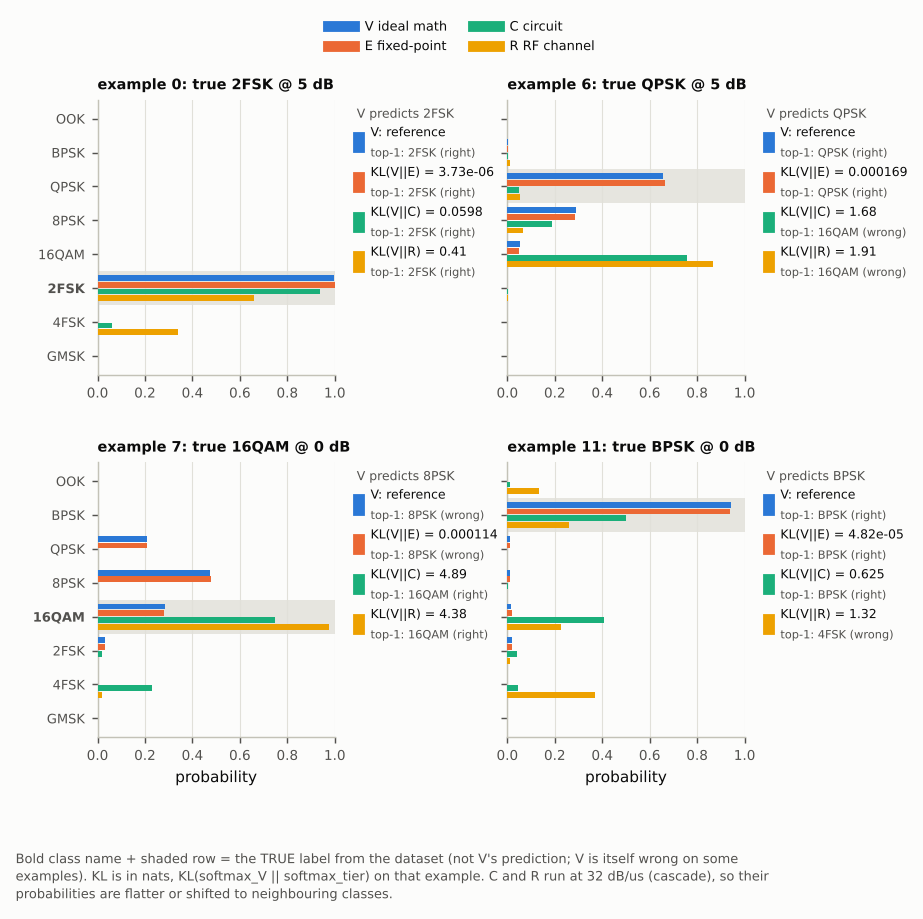

In [3]:
nb.show('fig4_outputs', run)

## Figure 5: sweeps

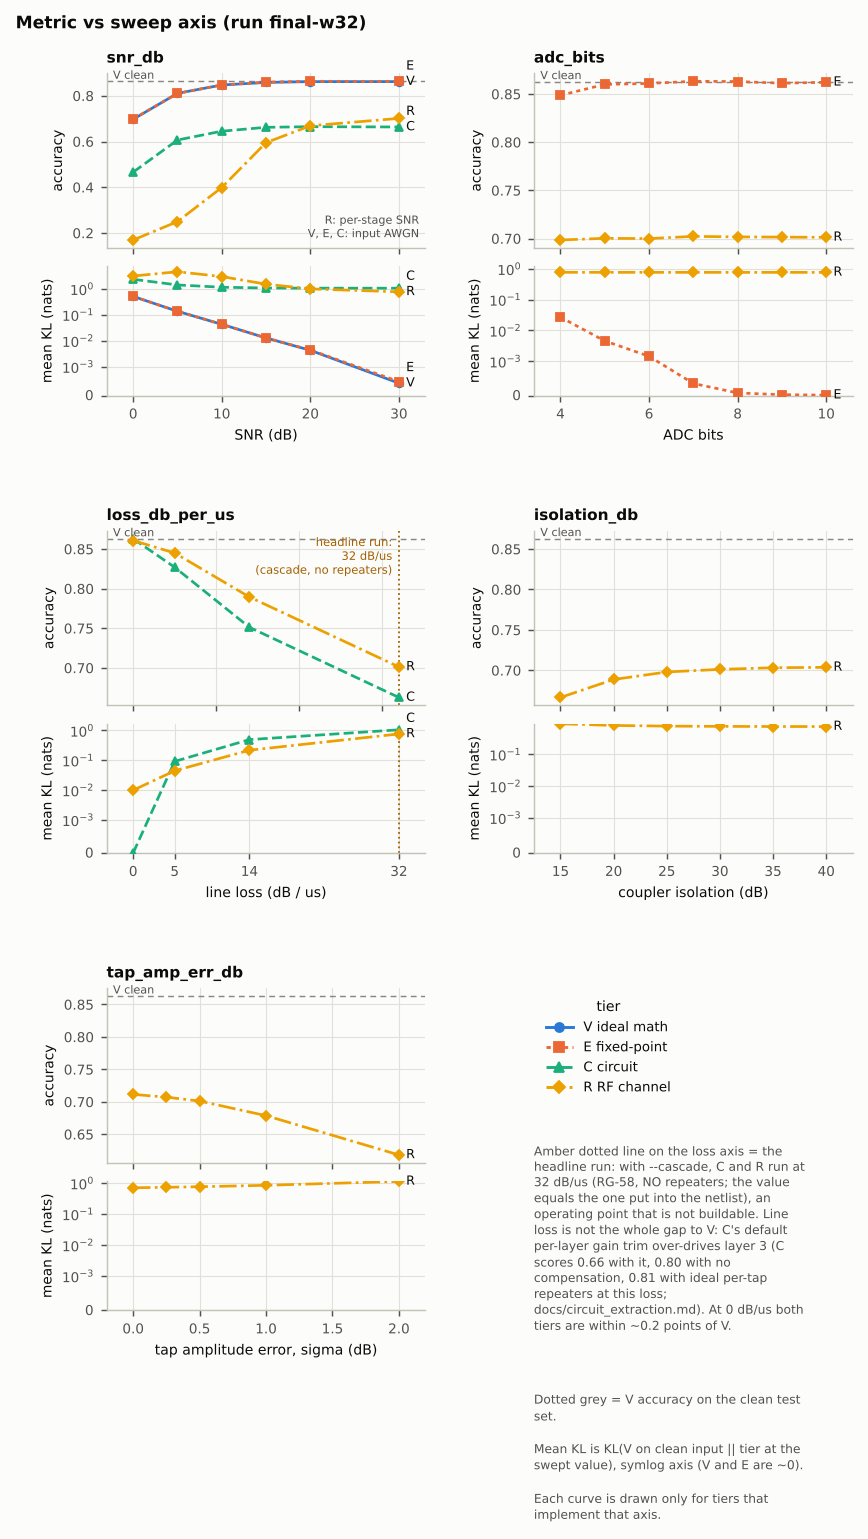

In [4]:
nb.show('fig5_sweeps', run)

**What the sweeps say.** E is flat down to 5 ADC bits. C and R are not bugs: at the headline operating point (`--cascade`: the fitted 32 dB/us line loss, equal to the netlist input, no repeaters; not buildable) they are 16-20 points below V, and for C most of that is its default per-layer gain trim rather than line loss (0.663 vs 0.804 with no compensation); at 0 dB/us they match V (0.863 / 0.861). V's own accuracy falls only below 10 dB input SNR. R's per-stage SNR axis is a different quantity from the input-AWGN axis of V/E/C (notebook 05).

## Figures 6 and 7: where the differences are

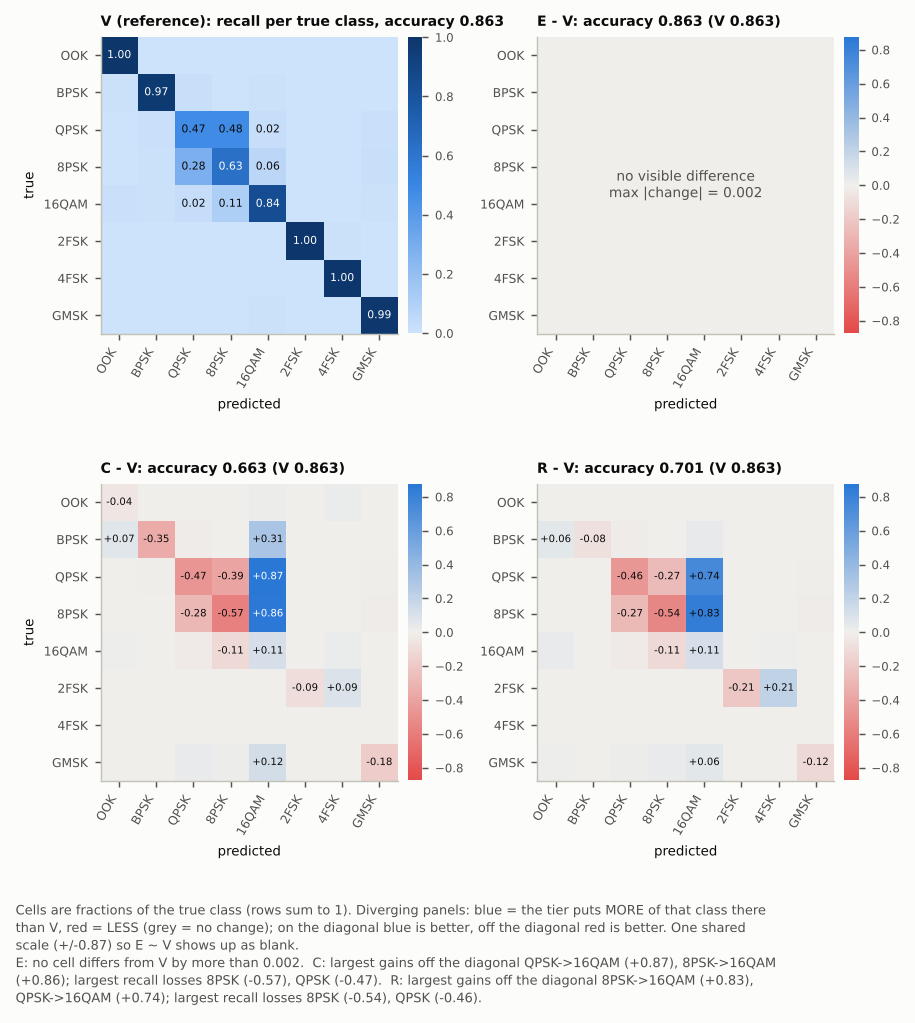

In [5]:
nb.show('fig6_confusion', run)

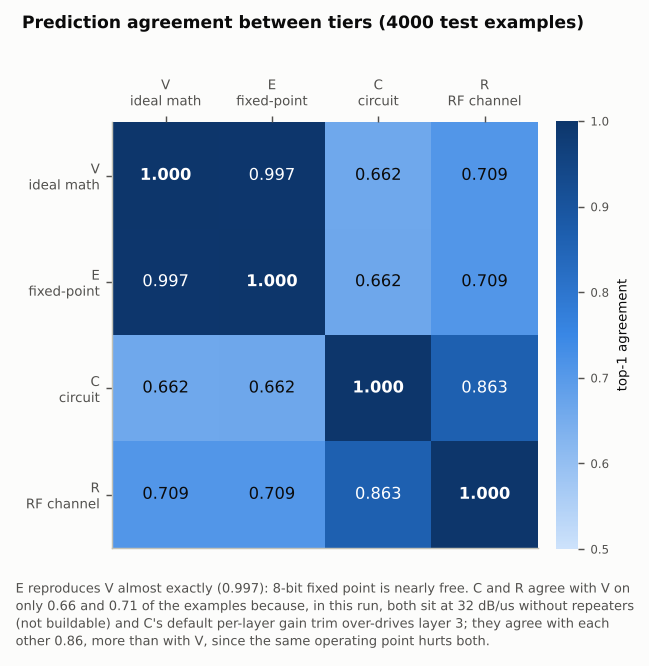

In [6]:
nb.show('fig7_agreement', run)

## The card the commentator reads

In [7]:
from dlnn.llm import card
cp = run.dir / "llm" / "card.txt"
ctext = cp.read_text() if cp.exists() else card.render_card(cmp)
print(f"card: {len(ctext)} chars, ~{card.approx_tokens(ctext)} tokens by card.approx_tokens (conservative 2.4 chars/token; budget in dlnn/llm/card.py: MAX_TOKENS={card.MAX_TOKENS}, MAX_CHARS={card.MAX_CHARS}); "
      f"{'within' if len(ctext) <= card.MAX_CHARS else 'OVER'} the character budget\n")
print(ctext)

card: 3484 chars, ~1452 tokens by card.approx_tokens (conservative 2.4 chars/token; budget in dlnn/llm/card.py: MAX_TOKENS=1500, MAX_CHARS=3500); within the character budget

CARD run=final-w32 task=modrec tiers=V,E,C,R
V is the reference (ideal math). Every metric 'vs_virtual' and every delta is relative to V.

TIERS
V (virtual, ideal math): status=ok tool=numpy-float32
   models: ideal unit delays; exact ternary sums; exact tanh; float32 arithmetic
   omits: every physical effect: loss, dispersion, noise, quantisation, saturation limits
E (emulated, fixed-point): status=ok tool=numpy-fixedpoint
   models: numpy fixed-point golden model (bit-true): 8-bit absmax ADC, int2 ternary weights, int32 accumulate, 256-entry tanh LUT -> int8, Q.15 scale / per-line scale, integer pool sum; Verilog RTL hw/rtl/tdl_…
   omits: RTL not simulated on the full test set (only 64 examples, numpy golden elsewhere); all analog effects (loss, dispersion, noise, coupler err…
C (circuit, SPICE-style): status=

## The commentary, with verification status (figure 8)

commentary read from final-w32: source = model, backend = qwen, numbers_verified = True, ids_verified = False


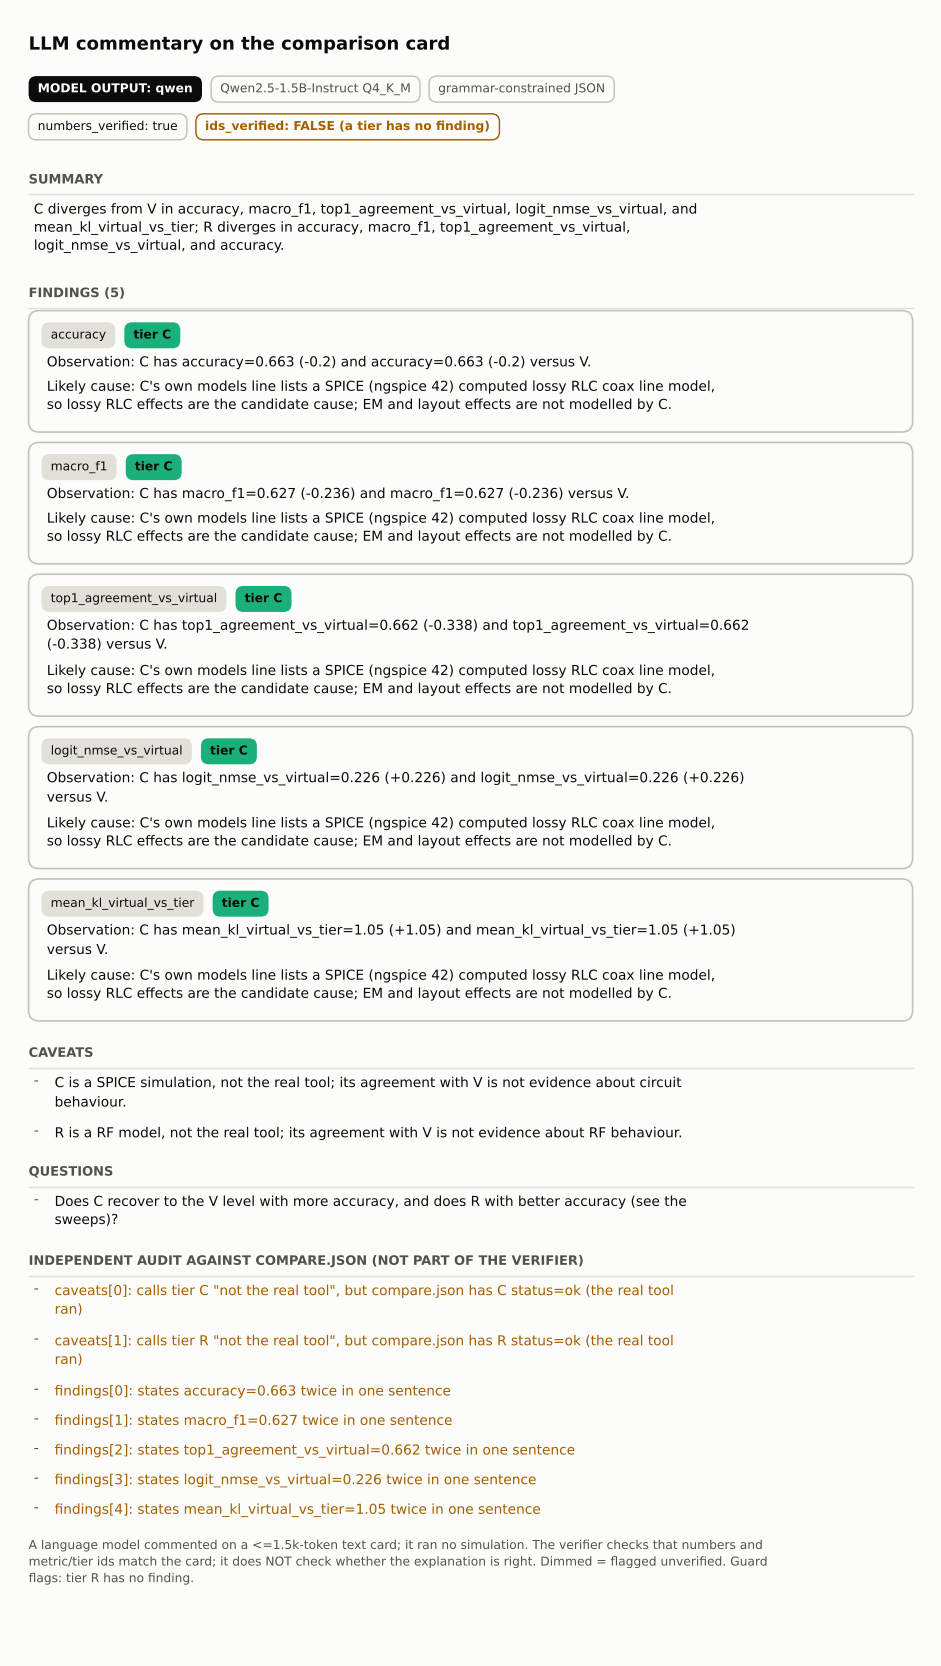

verifier: {'n_numbers': 25, 'retried': True, 'n_unverified_raw': 0, 'n_unverified_final': 0}
UNVERIFIED: findings token 'R' | 
independent audit against compare.json statuses: ['caveats[0]: calls tier C "not the real tool", but compare.json has C status=ok (the real tool ran)', 'caveats[1]: calls tier R "not the real tool", but compare.json has R status=ok (the real tool ran)', 'findings[0]: states accuracy=0.663 twice in one sentence', 'findings[1]: states macro_f1=0.627 twice in one sentence', 'findings[2]: states top1_agreement_vs_virtual=0.662 twice in one sentence', 'findings[3]: states logit_nmse_vs_virtual=0.226 twice in one sentence', 'findings[4]: states mean_kl_virtual_vs_tier=1.05 twice in one sentence']


In [8]:
lrun = nb.llm_run_dir()
com = json.loads((lrun / "llm" / "commentary.json").read_text())
print(f"commentary read from {lrun.name}: source = {com['source']}, backend = {com['backend']}, numbers_verified = {com.get('numbers_verified')}, ids_verified = {com.get('ids_verified')}")
if lrun != run.dir:
    print(f"(the headline run {run.dir.name} carries a template commentary; {lrun.name} is a run of the same model with real Qwen output)")
nb.show('fig8_llm', run, commentary=com)
ver = com.get("verification")
if ver:
    print("verifier:", {k: ver[k] for k in ("n_numbers", "retried", "n_unverified_raw", "n_unverified_final")})
for u in com.get("unverified", []):
    print("UNVERIFIED:", u["where"], "token", repr(u["token"]), "|", u["sentence"])
aud = figures.audit_commentary(com, run.status, run.cmp)
print("independent audit against compare.json statuses:", aud if aud else "no contradictions found")

In [9]:
# the template commentary (labelled as such), for contrast
tc = run.dir / "llm" / "commentary.json"
t = json.loads(tc.read_text())
if t["source"] == "template":
    print("headline run commentary is a TEMPLATE (backend 'null'), not model output:")
    nb.show('fig8_llm', run, commentary=t)

In [10]:
# optional: re-run the LLM now (needs the GGUF; off by default because it takes about a minute and the box is shared)
if os.environ.get("RUN_LLM") == "1" and nb.llm_available():
    from dlnn.llm import backend
    t0 = time.time()
    fresh = backend.get_backend("qwen").comment(cmp, ctext)
    print(f"live Qwen run took {time.time() - t0:.0f} s; source = {fresh['source']}, numbers_verified = {fresh.get('numbers_verified')}")
    nb.show('fig8_llm', run, commentary=fresh)
else:
    print("RUN_LLM != 1 (or the GGUF is missing): showing the saved commentary only. Set RUN_LLM=1 to run Qwen live.")

RUN_LLM != 1 (or the GGUF is missing): showing the saved commentary only. Set RUN_LLM=1 to run Qwen live.


**How to read the commentary.** The verifier checks every number and every `metric_id` / tier id against the card, retries once, and dims what is still wrong. It does **not** check whether an *explanation* is true: in the saved Qwen output the finding "C models a 6-bit ADC" is flagged (6 is not on the card), and a caveat calls R a "FALLBACK" although `compare.json` has `R: status ok` (the independent audit above catches that one). The saved commentary also has `ids_verified: false` (tier R has no finding), which the figure now shows next to `numbers_verified: true`. The cause of the C and R gap in this run (32 dB/us line loss with no repeaters, plus C's default per-layer gain trim) is **not** mentioned by the model; the card does not state the operating point. Treat the commentary as a summary of the card, never as analysis.